# Equipetrol Delivery: GPU (EC2) en Google Colab

Compila `delivery_sim` con CUDA, corre las pruebas de igualdad GPU = CPU en la GPU real, mide las aplicaciones
(`--headless --bench`, un CSV) y arma las tablas y los gráficos del informe desde los CSV.

**Antes de correr nada:** *Runtime → Change runtime type → T4 GPU → Save*. Cambiar el runtime borra los archivos:
después, *Runtime → Run all*. Todo corre en terminal: no hay ventana (`-DDELIVERY_WINDOW=OFF`, sin OpenCV).

Qué número sale de qué máquina (sección 2.2 del documento): las versiones de GPU salen de esta T4; el veredicto
compara contra la **CPU multihilo de la laptop** (su CSV está en el repo, en `docs/ec2/<aplicación>/laptop.csv`);
las versiones de CPU medidas acá dan la tabla secundaria "misma máquina".

In [1]:
# La máquina: GPU, driver, CUDA, compilador y CPU de Colab
!nvidia-smi --query-gpu=name,driver_version,clocks.max.sm,memory.total --format=csv
!nvcc --version | tail -2
!cmake --version | head -1
!g++ --version | head -1
!lscpu | grep -E 'Model name|^CPU\(s\)|Thread|Core'

name, driver_version, clocks.max.sm [MHz], memory.total [MiB]
Tesla T4, 580.82.07, 1590 MHz, 15360 MiB
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
cmake version 3.31.10
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
Thread(s) per core:                      2
Core(s) per socket:                      1


In [2]:
# El código: la rama de EC2 del repositorio (público). El hash de src/ no cambia con un --amend del mensaje:
# sirve para comprobar que lo medido es el código del commit.
BRANCH = "feat/ec2-gpu"
!rm -rf Delivery_Equipetrol && git clone -q -b {BRANCH} https://github.com/OjedaErwin123/Delivery_Equipetrol
!cd Delivery_Equipetrol && git log -1 --format='commit %h  %s' && echo "src/ = $(git rev-parse HEAD:src)"

commit 5b1d2b2  wip: R1 las motos más cercanas en la GPU + infraestructura de EC2
src/ = 026ce577c9d7679f232cbc199e162f889f36ca1f


In [3]:
# Compilar con CUDA (sm_75, la T4), Release, sin ventana. Unos minutos: Colab tiene 2 vCPU.
!cmake -S Delivery_Equipetrol -B build -DUSE_CUDA=ON -DDELIVERY_WINDOW=OFF -DCMAKE_BUILD_TYPE=Release 2>&1 | tail -3
!cmake --build build -j2 2>&1 | grep -iE 'warning|error|Built target (delivery_sim|gpu_)'

-- Configuring done (6.5s)
-- Generating done (0.1s)
-- Build files have been written to: /content/build
[ 13%] Built target delivery_sim
[ 93%] Built target gpu_smoke_check
[100%] Built target gpu_nearest_check


## Pruebas: GPU = CPU en la GPU real

`ctest` corre todas las pruebas del proyecto. Las `gpu_*_check` comparan el resultado de cada kernel con la versión
de CPU (exacto en enteros; en R1, la misma moto elegida, incluidos los empates).

In [4]:
!cd build && ctest -j2 2>&1 | tail -3
!./build/gpu_nearest_check

100% tests passed, 0 tests failed out of 36

Total Test time (real) =  24.57 sec
dispositivo: Tesla T4
subconjunto más grande devuelto: 35 motos (los empates en distancia entran todos)
el subconjunto de la GPU tiene más de `limit` motos: OK
el subconjunto contiene a las `limit` más cercanas de la CPU (con empates): OK
la decisión de la CPU dentro del subconjunto = nearestOf sobre todas: OK
por el hilo dueño: misma decisión que nearestOf: OK
error esperado: "GPU: más motos que la capacidad reservada o límite demasiado grande"
un error de la GPU llega por el future como excepción: OK
después del error, el hilo dueño sigue atendiendo: OK


## compute-sanitizer: memoria y memoria compartida

`memcheck` busca accesos fuera de rango o desalineados; `racecheck`, carreras en la memoria compartida (las
reducciones por bloque). Deben dar `ERROR SUMMARY: 0 errors`.

In [5]:
!compute-sanitizer --tool memcheck ./build/gpu_nearest_check 2>&1 | tail -2
!compute-sanitizer --tool racecheck ./build/gpu_nearest_check 2>&1 | tail -2
!compute-sanitizer --tool memcheck ./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --bench-once 2>&1 | tail -2

después del error, el hilo dueño sigue atendiendo: OK
========= ERROR SUMMARY: 0 errors
después del error, el hilo dueño sigue atendiendo: OK
========= RACECHECK SUMMARY: 0 hazards displayed (0 errors, 0 warnings)
r1_nearest n=100000: cpu_1=15.069849ms cpu_threadsx1=5.232344ms cpu_threadsx2=5.194322ms gpu_end_to_end=4.569535ms gpu_kernel=4.046848ms gpu_via_owner=4.873781ms
========= ERROR SUMMARY: 0 errors


## El bench: un CSV con una línea por corrida

`--bench` mide cada aplicación en un barrido de tamaños, con todas sus versiones intercaladas y 15 repeticiones
(después de una corrida de calentamiento). Cada corrida se compara con la referencia (columna `correct`).

In [6]:
!mkdir -p results
!./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --bench results/colab.csv
!echo "corridas incorrectas: $(grep -c ',no,' results/colab.csv)"

bench: Intel(R) Xeon(R) CPU @ 2.00GHz x2 | Tesla T4, 15 repeticiones por tamaño
r1_nearest n=100: cpu_1=0.009949ms cpu_threadsx1=0.016195ms cpu_threadsx2=0.021201ms gpu_end_to_end=0.085879ms gpu_kernel=0.047264ms gpu_via_owner=0.095843ms
r1_nearest n=300: cpu_1=0.031339ms cpu_threadsx1=0.030922ms cpu_threadsx2=0.034694ms gpu_end_to_end=0.093112ms gpu_kernel=0.055520ms gpu_via_owner=0.104274ms
r1_nearest n=1000: cpu_1=0.150265ms cpu_threadsx1=0.090027ms cpu_threadsx2=0.097797ms gpu_end_to_end=0.102752ms gpu_kernel=0.056512ms gpu_via_owner=0.118696ms
r1_nearest n=3000: cpu_1=0.452126ms cpu_threadsx1=0.245470ms cpu_threadsx2=0.246291ms gpu_end_to_end=0.122683ms gpu_kernel=0.058880ms gpu_via_owner=0.136823ms
r1_nearest n=10000: cpu_1=1.702813ms cpu_threadsx1=0.777948ms cpu_threadsx2=0.804592ms gpu_end_to_end=0.157401ms gpu_kernel=0.057344ms gpu_via_owner=0.191771ms
r1_nearest n=30000: cpu_1=5.521893ms cpu_threadsx1=2.338158ms cpu_threadsx2=2.334165ms gpu_end_to_end=0.292890ms gpu_kernel=0.

## Perfiles: nsys (línea de tiempo) y ncu (por kernel)

`nsys` muestra cuánto del tiempo de GPU es copia y cuánto kernel. `ncu` da ocupación, rendimiento de memoria y
cómputo y los datos del roofline de los kernels principales (una sola corrida: `--bench-once`).

In [7]:
!nsys profile --stats=true --force-overwrite true -o results/timeline ./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --bench-once 2>&1 | grep -A14 -E 'cuda_gpu_kern_sum|cuda_gpu_mem_time_sum' | head -40
# --bench-once lanza cada kernel dos veces por tamaño (calentamiento y medición), en el orden 100, 300, 1000,
# 3000, 10000, 30000, 100000: saltar 7 lanzamientos = la medición con 3000 motos (la ciudad); 13 = con 100000.
for size, skip in ((3000, 7), (100000, 13)):
    !ncu --set full -k regex:distancesAndBlockTop --launch-skip {skip} --launch-count 1 -f -o results/r1_nearest_{size} ./build/delivery_sim Delivery_Equipetrol/config/santa_cruz.json --headless --bench-once > /dev/null 2>&1
    print(f"===== distancesAndBlockTop con {size} motos")
    !ncu --import results/r1_nearest_{size}.ncu-rep --page details --section SpeedOfLight --section Occupancy --section LaunchStats 2>&1 | grep -vE '^\s*$' | head -60

[6/8] Executing 'cuda_gpu_kern_sum' stats report

 Time (%)  Total Time (ns)  Instances  Avg (ns)   Med (ns)  Min (ns)  Max (ns)  StdDev (ns)                                                  Name                                                
 --------  ---------------  ---------  ---------  --------  --------  --------  -----------  ----------------------------------------------------------------------------------------------------
     70.8        1,510,813         14  107,915.2  61,103.0    44,159   343,576    102,911.4  <unnamed>::distancesAndBlockTop(const Coordinates *, unsigned int, double, double, double *, unsign…
     27.1          577,650         14   41,260.7  31,807.0    30,687    66,431     14,484.6  <unnamed>::mergeTop(const double *, const unsigned int *, unsigned int, unsigned int, double, doubl…
      2.1           44,989         14    3,213.5   2,816.0     2,688     5,279        884.0  <unnamed>::collect(const double *, unsigned int, const double *, unsigned int *, 

## Tablas y gráficos (desde los CSV, nada escrito a mano)

Por aplicación y tamaño: mediana, mínimo y máximo de cada versión. El veredicto compara la GPU de punta a punta con
la mejor CPU multihilo de la **laptop**; la tabla de Colab-CPU es la comparación en la misma máquina.

In [8]:
import pandas as pd, matplotlib.pyplot as plt, pathlib
colab = pd.read_csv("results/colab.csv")
laptop_files = list(pathlib.Path("Delivery_Equipetrol/docs/ec2").glob("*/laptop.csv"))
laptop = pd.concat([pd.read_csv(f) for f in laptop_files]) if laptop_files else colab.iloc[0:0]
print("laptop:", laptop["machine"].iloc[0] if len(laptop) else "(todavía sin CSV de la laptop)")
print("colab: ", colab["machine"].iloc[0])

def summary(df):
    g = df.groupby(["application", "version", "threads", "size"])["ms"]
    return g.agg(median="median", min="min", max="max", runs="count").reset_index()

def best_cpu(s):
    cpu = s[s.version.isin(["cpu_1", "cpu_threads"])]
    return cpu.loc[cpu.groupby(["application", "size"])["median"].idxmin()].set_index(["application", "size"])

def table(app, cpu_source):
    s_cpu, s_gpu = summary(cpu_source), summary(colab)
    rows = []
    for size in sorted(s_gpu[s_gpu.application == app]["size"].unique()):
        pick = lambda s, v, t=None: s[(s.application == app) & (s.version == v) & (s["size"] == size) & ((s.threads == t) if t else True)]
        one = pick(s_cpu, "cpu_1")["median"].min()
        best = best_cpu(s_cpu).loc[(app, size)]
        kern = pick(s_gpu, "gpu_kernel")["median"].min()
        e2e = pick(s_gpu, "gpu_end_to_end")["median"].min()
        ok = (cpu_source[(cpu_source.application == app) & (cpu_source["size"] == size)].correct == "yes").all() and \
             (colab[(colab.application == app) & (colab["size"] == size)].correct == "yes").all()
        rows.append({"size": size, "CPU 1 hilo (ms)": one, f"CPU N hilos (ms)": best["median"], "N": int(best["threads"]),
                     "GPU kernel (ms)": kern, "GPU punta a punta (ms)": e2e,
                     "speedup kernel": best["median"] / kern, "speedup punta a punta": best["median"] / e2e,
                     "correcto": "sí" if ok else "NO"})
    return pd.DataFrame(rows)

for app in sorted(colab.application.unique()):
    print(f"\n=== {app}: CPU de la laptop (veredicto) ===")
    if len(laptop): display(table(app, laptop).round(4))
    print(f"=== {app}: CPU de Colab (misma máquina) ===")
    display(table(app, colab).round(4))

laptop: (todavía sin CSV de la laptop)
colab:  Intel(R) Xeon(R) CPU @ 2.00GHz x2 | Tesla T4

=== r1_nearest: CPU de la laptop (veredicto) ===
=== r1_nearest: CPU de Colab (misma máquina) ===


,size,CPU 1 hilo (ms),CPU N hilos (ms),N,GPU kernel (ms),GPU punta a punta (ms),speedup kernel,speedup punta a punta,correcto
0,100,0.0099,0.0099,1,0.0473,0.0859,0.2105,0.1158,sí
1,300,0.0313,0.0309,1,0.0555,0.0931,0.5570,0.3321,sí
2,1000,0.1503,0.0900,1,0.0565,0.1028,1.5931,0.8762,sí
3,3000,0.4521,0.2455,1,0.0589,0.1227,4.1690,2.0008,sí
4,10000,1.7028,0.7779,1,0.0573,0.1574,13.5663,4.9425,sí
5,30000,5.5219,2.3342,2,0.1018,0.2929,22.9308,7.9694,sí
6,100000,20.6489,7.6882,2,0.3491,0.8188,22.0215,9.3897,sí


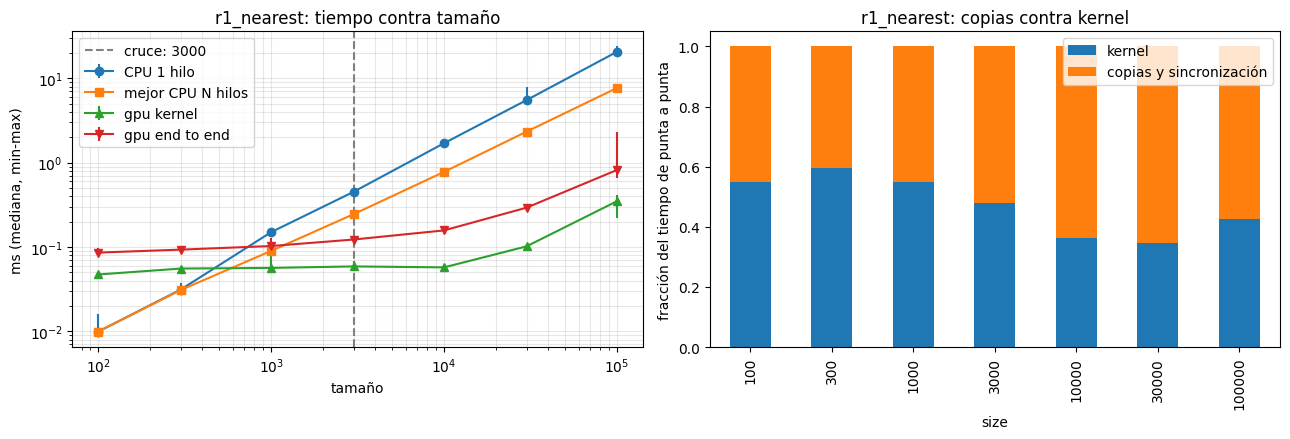

In [9]:
# Gráfico 1: tiempo contra tamaño, las cuatro versiones, ejes log-log (CPU de la laptop si está; si no, de Colab).
# Gráfico 2: qué parte del tiempo de GPU de punta a punta es copia y qué parte kernel.
for app in sorted(colab.application.unique()):
    cpu_src = laptop if len(laptop) else colab
    s_cpu, s_gpu = summary(cpu_src[cpu_src.application == app]), summary(colab[colab.application == app])
    best = best_cpu(s_cpu).reset_index()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    one = s_cpu[s_cpu.version == "cpu_1"]
    ax[0].errorbar(one["size"], one["median"], yerr=[one["median"] - one["min"], one["max"] - one["median"]], marker="o", label="CPU 1 hilo")
    ax[0].errorbar(best["size"], best["median"], marker="s", label="mejor CPU N hilos")
    for v, m in (("gpu_kernel", "^"), ("gpu_end_to_end", "v")):
        g = s_gpu[s_gpu.version == v]
        ax[0].errorbar(g["size"], g["median"], yerr=[g["median"] - g["min"], g["max"] - g["median"]], marker=m, label=v.replace("_", " "))
    e2e = s_gpu[s_gpu.version == "gpu_end_to_end"].set_index("size")["median"]
    wins = [n for n in e2e.index if n in best.set_index("size").index and e2e[n] < best.set_index("size").loc[n, "median"]]
    if wins:
        ax[0].axvline(min(wins), color="gray", ls="--", label=f"cruce: {min(wins)}")
    ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("tamaño"); ax[0].set_ylabel("ms (mediana, min-max)")
    ax[0].set_title(f"{app}: tiempo contra tamaño"); ax[0].legend(); ax[0].grid(True, which="both", alpha=.3)
    kern = s_gpu[s_gpu.version == "gpu_kernel"].set_index("size")["median"]
    share = pd.DataFrame({"kernel": kern / e2e, "copias y sincronización": 1 - kern / e2e})
    share.plot.bar(stacked=True, ax=ax[1]); ax[1].set_ylabel("fracción del tiempo de punta a punta"); ax[1].set_title(f"{app}: copias contra kernel")
    plt.tight_layout(); plt.savefig(f"results/{app}.png", dpi=120); plt.show()

In [10]:
# Barrido de hilos de la CPU multihilo (speedup contra 1 hilo), en la laptop si está y en Colab.
for name, df in (("laptop", laptop), ("colab", colab)):
    if not len(df): continue
    s = summary(df[df.version == "cpu_threads"])
    for app in sorted(s.application.unique()):
        piv = s[s.application == app].pivot(index="size", columns="threads", values="median")
        display((piv[1].values[:, None] / piv).round(2).rename_axis(f"{name} {app}: speedup contra 1 hilo", axis=1))

colab r1_nearest: speedup contra 1 hilo,1,2
size,,
100,1.0,0.76
300,1.0,0.89
1000,1.0,0.92
3000,1.0,1.00
10000,1.0,0.97
30000,1.0,1.00
100000,1.0,1.02


## Guardar los resultados

Colab borra todo al cerrar la sesión. La celda arma `results.zip` (CSV, gráficos y reportes de nsys y ncu) para
bajarlo; si se monta Google Drive, también lo copia ahí.

In [11]:
!cd Delivery_Equipetrol && git rev-parse HEAD:src > ../results/src_tree.txt
!zip -qr results.zip results && ls -la results.zip
from google.colab import files
files.download("results.zip")
# from google.colab import drive; drive.mount("/content/drive"); !cp results.zip /content/drive/MyDrive/

-rw-r--r-- 1 root root 504318 Nov 20 03:55 results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>